# AMD［超威半导体］专题：完整实训与已记录结果

本专题新增厨房操作与灵巧手两条正式训练、评估流程。笔记本内保存真实指标、对照表与视频，打开即可查看；配置、计算和绘图代码保留，可在相应设备重新执行。

先阅读本笔记本，再选择 [厨房完整实训](17_robocasa365_amd_train_eval.ipynb) 或 [灵巧手完整实训](18_dexjoco_amd_train_eval.ipynb)。两本都包含基座与新权重对照、恢复方法、完整时长评估和失败视频。

## 数据到结果

源码与依赖固定 → 原生设备预检 → 全数据审计／统计 → 正式梯度训练 → 本次检查点及身份校验 → 基座和新权重各 20 回合闭环评估 → 同种子对照、曲线和视频。

全数据是采样来源范围；目标步数由实验配方指定，不等于已经完整遍历所有数据，也不保证收敛。

In [1]:
from pathlib import Path
import sys, json
TOPIC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/amd_benchmarks').is_dir())
sys.path.insert(0, str(TOPIC / 'code'))
from amd_benchmarks.evidence import training_summary, compare_policies, table, show_recorded_videos
RESULTS = TOPIC / 'notebooks/results'


## 官方计算配置与本次实验的对应关系

[官方论文第二版](https://arxiv.org/html/2605.16257v2)报告训练使用 NVIDIA［英伟达］A6000 和 L40 显卡，部署使用 NVIDIA［英伟达］RTX 4090 显卡；没有明确给出单任务训练小时数或各模型使用的显卡数量。[官方模型卡](https://huggingface.co/DexJoCo/DexJoCo-Pi05)给出单臂 30000 步、双臂及多任务 60000 步；[官方训练配置](https://github.com/brave-eai/dexjoco/blob/main/openpi/config.yaml)默认批量 32，并把批量 1 注释为测试用途。

| 比较项 | 官方单臂配方 | 本次灵巧手设备实验 |
| --- | --- | --- |
| 更新步数 | 30000 | 30000 |
| 每步批量 | 32 | 1，梯度累积 1，有效批量 1 |
| 样本呈现次数 | 960000 | 30000，允许重复采样 |
| 起始权重 | 通用 `pi05_base/params` | 官方已经适配浇花任务的 `pi05_dexjoco_ckpt/water_plant` |
| 评估规模 | 每任务每设置 3 个种子，每种子 50 回合 | 起始任务权重及本次继续训练权重，各 20 回合，种子 100–119 |

**本次是从官方任务权重继续适配的完整设备工作流，不能称作从通用基座按论文配方重新训练。** 下方对照中的“基座”指本次起始任务权重，不是从未见过该任务的通用模型。两组各 20 回合使用官方任务时长，但回合数量与论文不同。

本次 30000 次更新已经完成，训练阶段实测 65452.774 秒，即约 18 小时 11 分钟；这是本机小批量配方的实测耗时，不是官方耗时。原生检查点从零编号，最终目录编号为 29999，对应第 30000 次更新。两天内完成单任务适配与课程整理是可行的；论文还覆盖 11 个任务、多种策略、随机化与消融实验，不能以单任务耗时代表整篇论文计算需求。


## 严格加载修正后的完整结果

| 实验 | 起始权重 | 本次训练后权重 | 正式评估 |
| --- | --- | --- | --- |
| 厨房，3000 次更新 | 14/20（70%） | 14/20（70%） | 相同种子 100–119，完整 750 步上限 |
| 灵巧手，30000 次更新 | 5/20（25%） | 3/20（15%） | 严格加载、计时前预热，官方异步动作时序，完整任务终止条件 |

**官方异步条件下，本轮继续训练未显示效果提升。** 灵巧手点估计下降 10 个百分点；同种子改善 [111, 116]、退步 [101, 102, 105, 113]。每组只有 20 回合，不能据此断言稳定退化或代表论文完整成绩。训练曲线不能代替闭环成功率。

已定位并修复此前官方权重 0/20 的加载缺陷：辅助代码错误地关闭 LoRA［低秩适配］分支，上游加载器又静默丢弃结构之外的参数。文件内容指纹一致不等于模型完整加载。当前根据检查点元数据选择结构，禁止丢弃额外参数；两组的实际加载审计均确认 20 个任务适配张量，两个模型分支都保留适配器。原 0/20 基线无效，旧对照只作排错历史，不能代表完整官方权重的性能。

当前两组分别预热 19.36 秒、18.45 秒，均恢复随机数状态。两套均完成全数据准备、连续有限的完整目标更新步数和相同种子的两组完整评估；本次重评估复用同一份 30000 步权重，没有重复训练。

### 归一化、动作接口与推理时延

官方与本次统计均为状态 23 维、动作 22 维，分位数最大绝对差约 0.00318，暂未发现明显维度或尺度错误。源码级动作检查确认 22 维策略动作转换到 23 维模拟器动作时，三维位置、16 个手关节保持不变，旋转矩阵往返误差约 3.33×10⁻¹⁶；这只是接口数学检查，不冒充模型推理或任务成功率。

正确加载并预热后的独立种子 100 诊断中，推理中位耗时约 0.897 秒，首次调用约 0.912 秒，已经没有长时间的首次编译。但完整 1000 个仿真步中，仅 552 步执行策略动作，448 步保持姿态；30 步动作块到达时通常只剩 9–13 步可用。诊断单独保存，不计入 20 个正式种子的分母。这说明稳态等待仍显著改变实际动作执行，不能把剩余失败全归因于训练或模型质量。

独立的等待时钟对照已完成：起始权重 12/20（60%），训练后权重 14/20（70%），相同种子 100–119。训练后点估计增加 10 个百分点，但每组只有 20 回合，不能据此宣称稳定提升或严格复现论文成绩。只在等待新动作、缓冲区为空时暂停仿真时钟，保留官方动作合并、观测时间戳、真实环境步进和成功条件。训练与权重均未改变，没有再次训练。它与官方异步评估属于不同部署条件，不能替换官方异步的 5/20 对 3/20。该模式让模拟器等待设备计算，并未缩短实际推理耗时；视频按物理仿真步播放，不展示等待的墙钟时间，逐回合等待休眠累计与完整墙钟时间另存于 `clock_audit.json`，等待休眠累计不含循环处理开销。真实机器人能否保持同等行为仍需另行验证。

### 旧日志与成功视频

旧单任务目录中的浇花种子 0–3 均有成功标记；下方单列旧种子 0 的完整成功视频。另有官方多任务权重的 11 项推理演示，固定种子 0 每项一回合，共 5/11 成功；后续搜索种子得到浇花种子 2 成功。搜索后的成功片段不等于固定种子成功率，运行多任务权重也不代表自己做过多任务联合训练。所有历史视频都与本轮正式分母分开。

自动更新服务此前因内存耗尽退出。本次管理员操作已暂停两个自动更新定时器，当前服务不运行；如需恢复触发器，执行 `sudo systemctl start apt-daily.timer apt-daily-upgrade.timer`。教程不会自动执行系统维护操作。记录在 `results/system/system-maintenance-20261025.json`。


## 正式实验范围与配置

In [2]:
table(['任务','训练数据','正式更新步数','批量／累积／有效批量','评估种子','官方时长'], [['厨房','502 回合／131904 帧',3000,'1／1／1','100–119，基座与新权重各 20 回合','750 步上限'],['灵巧手','100 回合／27745 帧',30000,'1／1／1','100–119，基座与新权重各 20 回合','官方任务终止条件']])


任务,训练数据,正式更新步数,批量／累积／有效批量,评估种子,官方时长
厨房,502 回合／131904 帧,3000,1／1／1,100–119，基座与新权重各 20 回合,750 步上限
灵巧手,100 回合／27745 帧,30000,1／1／1,100–119，基座与新权重各 20 回合,官方任务终止条件


## 厨房：已记录的完整正式对照

本次是投影相关层适配，201437184 个可训练参数。基座与新权重均为 14/20 成功，总体未提升；不能把梯度训练完成描述为策略效果提升。详细曲线、20 行配对结果和成功／失败视频保存在厨房笔记本。

In [3]:
training_summary(RESULTS / 'robocasa')
compare_policies(RESULTS / 'robocasa')


记录项,实测或配置
任务,PickPlaceCounterToCabinet
数据回合／帧数,502 / 131904
真实已记录更新／目标,3000 / 3000
实际批量／梯度累积／有效批量,1 / 1 / 1
学习率或峰值学习率,1e-05
可训练参数,201437184
最后记录损失,0.034190669655799866
正式训练状态,完成
原始证据目录,/home/aup/amd-notebook-work/runs/robocasa-formal-20261023-v1
实测训练阶段耗时／小时,0.424


样本更新次数／数据帧数： 0.0227
该比值用于理解数据使用规模；随机有放回采样不保证每个样本都已遍历。
本次权重内容指纹： 9d64f32346807e6071261b150434cbcaa0765c3a4a0569617e5bf51f9ce000fe
参数更新前后指纹是否不同： True


策略,成功回合／完整分母,成功率,权重指纹前缀
原始基座,14 / 20,70.0%,181b64f0bf07e46b
本次训练后权重,14 / 20,70.0%,9d64f32346807e60


种子,基座,训练后,同种子变化
100,成功,成功,相同
101,成功,失败,退步
102,失败,失败,相同
103,成功,成功,相同
104,成功,成功,相同
105,失败,成功,改善
106,失败,失败,相同
107,成功,成功,相同
108,成功,成功,相同
109,失败,失败,相同


总体成功率差： +0.0 个百分点
本结果只适用于记录的单任务、种子、划分及配方；相同成功率不代表每个回合行为相同。


## 灵巧手：正式训练进度

采用上游冻结过滤器，466957072 个可训练参数，包含视觉与低秩适配部分。全 27745 帧归一化统计已完成。正式训练和两组完整评估已完成；严格加载主对照为 5/20 对 3/20，旧加载器的 0/20 基线仅作为缺陷历史保留。

In [4]:
training_summary(RESULTS / 'dexjoco')
compare_policies(RESULTS / 'dexjoco')


记录项,实测或配置
任务,water_plant
数据回合／帧数,100 / 27745
真实已记录更新／目标,30000 / 30000
实际批量／梯度累积／有效批量,1 / 1 / 1
学习率或峰值学习率,1e-05
可训练参数,466957072
最后记录损失,0.00023379144840873778
正式训练状态,完成
原始证据目录,/home/aup/amd-notebook-work/runs/dexjoco-formal-20261023-v1
实测训练阶段耗时／小时,18.181


样本更新次数／数据帧数： 1.0813
该比值用于理解数据使用规模；随机有放回采样不保证每个样本都已遍历。
本次权重内容指纹： 7cc8487f7609b05a255c6a942ff4f0f468302bf2bd6a08fafd3d4c7870115761
参数更新前后指纹是否不同： True


策略,成功回合／完整分母,成功率,权重指纹前缀
官方起始任务权重,5 / 20,25.0%,21640047e97354a6
本次训练后权重,3 / 20,15.0%,7cc8487f7609b05a


策略,适配张量数,允许静默丢弃参数,计时前预热／随机数恢复
官方起始任务权重,20,False,True / True
本次训练后权重,20,False,True / True


种子,基座,训练后,同种子变化
100,失败,失败,相同
101,成功,失败,退步
102,成功,失败,退步
103,失败,失败,相同
104,成功,成功,相同
105,成功,失败,退步
106,失败,失败,相同
107,失败,失败,相同
108,失败,失败,相同
109,失败,失败,相同


总体成功率差： -10.0 个百分点
本结果只适用于记录的单任务、种子、划分及配方；相同成功率不代表每个回合行为相同。


## 固定源码与环境分工

交互笔记本、厨房训练、灵巧手模型训练和灵巧手模拟器分别选择对应解释器。灵巧手模型使用原生 JAX［高性能数组计算框架］设备后端；处理器版张量库仅处理数据与视频。禁止用处理器模型推理冒充设备验收。

源码提交和内容指纹如下；精确安装版本分别保存于 `reproducibility/environment-robocasa.txt` 与 `reproducibility/environment-dexjoco.txt`。训练笔记本已内嵌关键安装命令及依赖说明。

In [5]:
versions = json.loads((TOPIC / 'reproducibility/source-manifest.json').read_text())
table(['组件','来源','提交或兼容参考提交'],[[key,value['source_url'],value.get('commit') or value.get('reference_commit')] for key,value in versions.items()])


组件,来源,提交或兼容参考提交
gr00t,https://github.com/robocasa-benchmark/Isaac-GR00T,9d7d7a9eb7ad30bd8ce30448d9ab53a918b45b10
robocasa,https://github.com/robocasa/robocasa,b4684e6ee37d377cc392e98302a6b916d588b415
robosuite,https://github.com/ARISE-Initiative/robosuite,5ce6643f3092639d08f7b0f90ed1c6a84f50552c
dexjoco,https://github.com/Ethan-Chen-plus/dexjoco,46fcd70db460b3be5487387adab2aaf3e2e7b74f
lerobot,https://github.com/huggingface/lerobot,00b5f65752e1e5882f96c99a34e1d8b6d5d67f11


## 磁盘与统一内存：实际问题和复现约定

设备曾因可再生成的数据缓存占满磁盘。清理前核对了原始文件存在、大小与文件头，并确认没有活动进程打开目标缓存；只删除 7 个派生缓存，原始数据、基座和训练产物保留。不要直接复制本次缓存删除路径用于其他机器，也不要在笔记本自动删除用户缓存。

灵巧手一份原生检查点约 8.9 GiB，保存时需要新旧副本空间。正式配置要求至少 24 GiB 空闲磁盘，保留最新完整检查点。厨房增量检查点约 2.3 GiB，恢复还需要原始基座。

自动更新进程曾多次异常占用内存，系统日志确认因内存耗尽被终止，不能称作更新成功。软件包审计未报告未配置的软件包。资源不足时应诊断实际竞争来源，不应停止其他训练；自动更新维护操作需要设备管理员权限。

In [6]:
audit=json.loads((RESULTS/'system/storage_cleanup_result.json').read_text())
print(json.dumps(audit,ensure_ascii=False,indent=2))
print('整本执行证据：')
print((RESULTS/'system/dexjoco-full-e2e-result.json').read_text())


{
  "time_unix": 1792716497.510573,
  "removed_rebuildable_bytes": 55597783543,
  "cache_directories": 7,
  "verified_retained_source_files": 904,
  "free_gib_after": 54.693267822265625,
  "selection_manifest": "cache_cleanup_selection.json"
}
整本执行证据：
{
  "state": "complete",
  "code_cells": 10,
  "execution_counts": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10
  ],
  "scope": "single fresh kernel, all workload stages enabled, no resumed cells",
  "notebook": "/home/aup/amd-notebook-work/course/notebooks/executed_18_full_e2e_20261023.ipynb"
}


## 连续运行与恢复

两套正式任务使用持久化串行执行器；每个阶段保存状态。资源不足时排队，不重复启动负载。中断后从完整检查点恢复；未提交的末尾训练指标归档，不与恢复后的同一步重复计数。

已准备好的设备可通过清单串行执行全部正式流程。首次请修改各运行配置中的新目录和本机路径；不要同时通过两本笔记本与清单重复启动相同任务。以下为可执行入口，默认关闭，阅读模式不会启动训练。

In [7]:
import os, subprocess
RUN_FULL_SERIES = False
manifest = TOPIC / 'reproducibility/pipeline-device-manifest.json'
if RUN_FULL_SERIES:
    env=os.environ.copy(); env['PYTHONPATH']=str(TOPIC/'code')
    subprocess.run([sys.executable,'-u','-m','amd_benchmarks.pipeline','--manifest',str(manifest)],env=env,check=True)
else:
    print('完整串行执行关闭。单任务完整运行入口见两本训练笔记本。')


完整串行执行关闭。单任务完整运行入口见两本训练笔记本。


## 正式验收标准

- 3000／30000 次真实更新，指标连续且有限，保存本次训练权重与内容指纹。
- 两组使用同一任务、同一官方划分、同一完整时长、相同 20 个种子，逐回合分母完整。
- 基座与训练后成绩分开；成功和失败视频均保留，不用短程验收、旧权重或历史比赛面板补齐。
- 两套完整执行均已结束；结果区明确区分流程执行完成与任务效果未复现。

## 证据与便携性

`notebooks/results/` 保存指标、配置、内容指纹、逐回合结果和代表性视频，不包含大模型权重与原始数据。笔记本输出嵌入了图表和所选视频，单独打开即可阅读；重新执行阅读模式须保留配套 `results/` 和 `code/`。完整复现另需按源码与资源单元准备数据、基座及设备环境。

当前资料包含来自已有正式任务的只读证据，以及一次全新内核的 20 步整本执行证明。后者只证明执行链路；最终实验仍须完成正式目标和完整对照。

## 等待时暂停仿真：独立完整部署条件对照

以下两组均完成 20 个固定种子；与前面的官方异步成绩分开展示。视频来自本条件实际记录。


/home/aup/envs/robocasa365-rocm-py312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


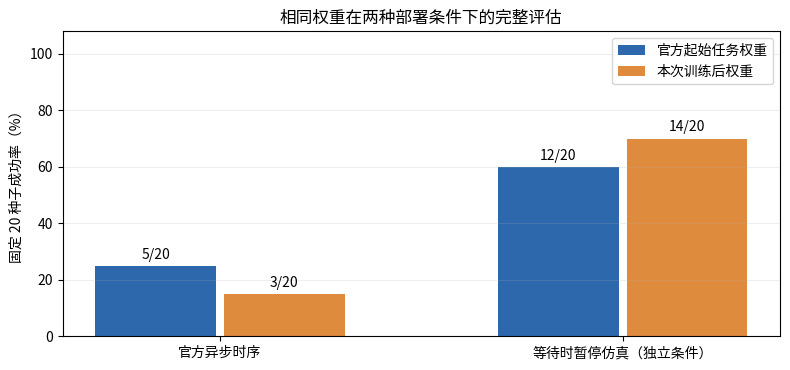

每组各 20 个固定种子；暂停仿真没有提高设备推理速度，不能替代官方异步成绩。


策略,成功回合／完整分母,成功率,权重指纹前缀
官方起始任务权重,12 / 20,60.0%,21640047e97354a6
本次训练后权重,14 / 20,70.0%,7cc8487f7609b05a


策略,适配张量数,允许静默丢弃参数,计时前预热／随机数恢复
官方起始任务权重,20,False,True / True
本次训练后权重,20,False,True / True


种子,基座,训练后,同种子变化
100,成功,成功,相同
101,成功,成功,相同
102,成功,失败,退步
103,失败,失败,相同
104,失败,成功,改善
105,成功,失败,退步
106,失败,失败,相同
107,成功,失败,退步
108,成功,成功,相同
109,失败,成功,改善


总体成功率差： +10.0 个百分点


...

等待列为缓冲区为空时休眠时间之和，未包含循环处理开销；墙钟列包含完整回合耗时。视频按物理仿真步播放，此条件不代表实时推理性能。
本结果只适用于记录的单任务、种子、划分及配方；相同成功率不代表每个回合行为相同。


**官方起始任务权重 · 种子 100 · 成功**

**官方起始任务权重 · 种子 103 · 失败**

**本次训练后权重 · 种子 100 · 成功**

**本次训练后权重 · 种子 102 · 失败**

In [8]:
CLOCK_RECORDED = TOPIC / 'notebooks/results/dexjoco_clock'
from amd_benchmarks.evidence import plot_deployment_conditions
plot_deployment_conditions(TOPIC / 'notebooks/results/dexjoco', CLOCK_RECORDED)
compare_policies(CLOCK_RECORDED)
show_recorded_videos(CLOCK_RECORDED)
